# Gauss-Hermite-Quadratur

Für die Hermite-Quadratur verwenden wir die explizit definierte Gewichtsfunktion
$$\omega(x) = e^{-x^2}.$$

Die Quadratur approximiert damit Integrale der Form
$$\int_{-\infty}^{\infty} f(x)\,\omega(x)\,dx
  \approx \sum_{i=1}^n w_i f(x_i).$$

`scipy.special.roots_hermite` liefert die Nullstellen $x_i$ der Hermite-Polynome und die zu dieser Gewichtsfunktion gehörenden Gewichte $w_i$.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.special as sp

from scipy.integrate import quad

In [7]:
f = lambda x: np.sin(2 * np.pi * x) / ((x - 3)**2 + 0.1)
omega = lambda x: np.exp(-x**2)

n = 5
N = 500
max_n = 100
X = np.linspace(-5, 5, N)

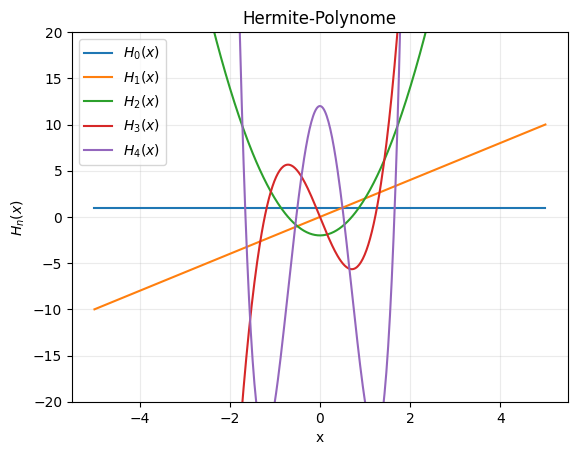

In [8]:
for i in range(n):
    y = sp.eval_hermite(i, X)
    plt.plot(X, y, label=rf'$H_{i}(x)$')

plt.title('Hermite-Polynome')
plt.xlabel('x')
plt.ylabel(r'$H_n(x)$')
plt.ylim(-20, 20)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

Die folgenden Plots zeigen die Hermite-Knoten und die zugehörigen Gewichte. Die Gewichte sind bereits für die explizite Gewichtsfunktion $\omega(x)=e^{-x^2}$ berechnet.

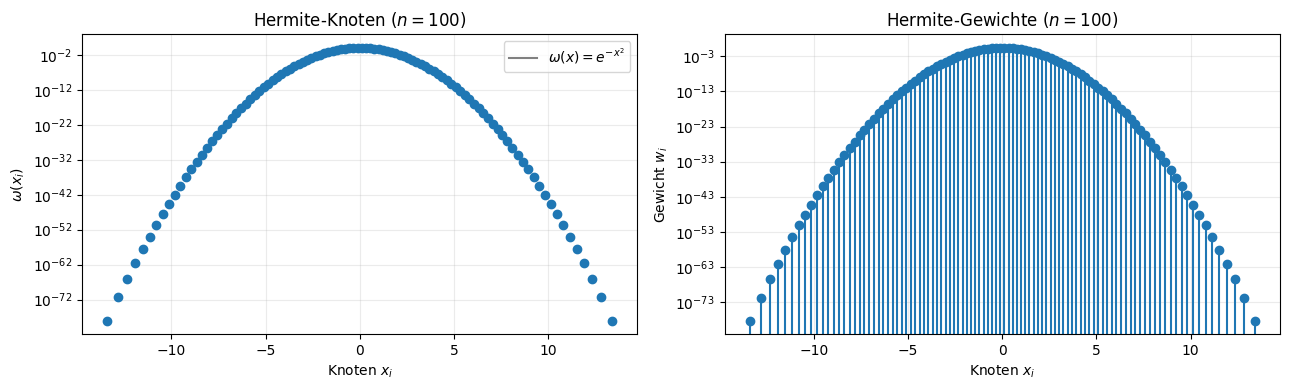

In [12]:
nodes, weights = sp.roots_hermite(max_n)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].semilogy(X, omega(X), color='gray', label=r'$\omega(x)=e^{-x^2}$')
axes[0].scatter(nodes, omega(nodes), color='tab:blue', zorder=3)
axes[0].set_title(f'Hermite-Knoten ($n={max_n}$)')
axes[0].set_xlabel('Knoten $x_i$')
axes[0].set_ylabel(r'$\omega(x_i)$')
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].semilogy()
axes[1].stem(nodes, weights, basefmt='k-')
axes[1].set_title(f'Hermite-Gewichte ($n={max_n}$)')
axes[1].set_xlabel('Knoten $x_i$')
axes[1].set_ylabel('Gewicht $w_i$')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

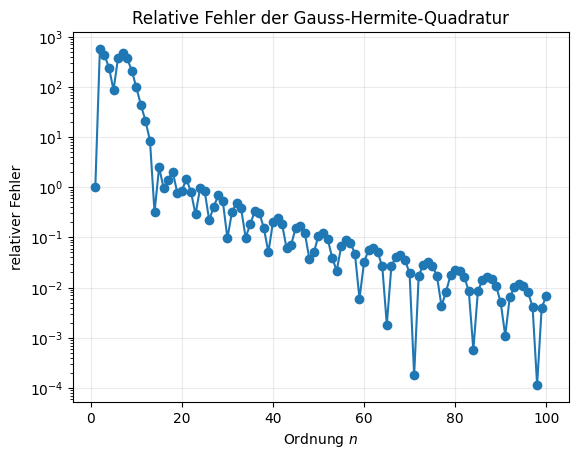

Exaktes Referenzintegral: -0.000171191499

n	Approximation	rel. Fehler
1:	  0.00000000	 1.00e+00
2:	 -0.09774051	 5.70e+02
3:	  0.07345889	 4.30e+02
4:	 -0.04134256	 2.40e+02
5:	 -0.01503444	 8.68e+01
6:	  0.06536919	 3.83e+02
7:	 -0.08076182	 4.71e+02
8:	  0.06278259	 3.68e+02
9:	 -0.03618640	 2.10e+02
10:	  0.01656745	 9.78e+01
11:	 -0.00767098	 4.38e+01
12:	  0.00346375	 2.12e+01
13:	 -0.00162409	 8.49e+00
14:	 -0.00011725	 3.15e-01
15:	  0.00025512	 2.49e+00
16:	 -0.00033592	 9.62e-01
17:	 -0.00041339	 1.41e+00
18:	  0.00017692	 2.03e+00
19:	 -0.00030213	 7.65e-01
20:	 -0.00031710	 8.52e-01
21:	  0.00007635	 1.45e+00
22:	 -0.00030955	 8.08e-01
23:	 -0.00022020	 2.86e-01
24:	 -0.00000804	 9.53e-01
25:	 -0.00031557	 8.43e-01
26:	 -0.00013347	 2.20e-01
27:	 -0.00010069	 4.12e-01
28:	 -0.00028858	 6.86e-01
29:	 -0.00008157	 5.24e-01
30:	 -0.00018756	 9.56e-02
31:	 -0.00022571	 3.18e-01
32:	 -0.00008657	 4.94e-01
33:	 -0.00023658	 3.82e-01
34:	 -0.00015420	 9.93e-02
35:	 -0.00014017	 1.

In [10]:
approx = []
orders = np.arange(1, max_n + 1)

for order in orders:
    x, w = sp.roots_hermite(order)
    approx.append(np.sum(w * f(x)))

q = quad(lambda x: f(x) * omega(x), -np.inf, np.inf)[0]
errors = np.abs((np.array(approx) - q) / q)

plt.semilogy(orders, errors, 'o-')
plt.title('Relative Fehler der Gauss-Hermite-Quadratur')
plt.xlabel('Ordnung $n$')
plt.ylabel('relativer Fehler')
plt.grid(alpha=0.25)
plt.show()

print(f'Exaktes Referenzintegral: {q:.12f}')
print('\nn\tApproximation\trel. Fehler')
for order, value, error in zip(orders, approx, errors):
    print(f'{order}:\t{value:>12.8f}\t{error:>9.2e}')